<a href="https://colab.research.google.com/github/Rajde13/Rajdeep-Deb/blob/main/Phase_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

2. Load Dataset

In [2]:
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Fishing.csv"

df = pd.read_csv(url)

df.head()

,rownames,mode,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
0,1,charter,182.930,0.5391,157.930,157.930,157.930,182.930,0.0678,0.0503,0.2601,0.5391,7083.3317
1,2,charter,34.534,0.4671,15.114,15.114,10.534,34.534,0.1049,0.0451,0.1574,0.4671,1249.9998
2,3,boat,24.334,0.2413,161.874,161.874,24.334,59.334,0.5333,0.4522,0.2413,1.0266,3749.9999
3,4,pier,15.134,0.0789,15.134,15.134,55.930,84.930,0.0678,0.0789,0.1643,0.5391,2083.3332
4,5,boat,41.514,0.1082,106.930,106.930,41.514,71.014,0.0678,0.0503,0.1082,0.3240,4583.3320


Check the dataset:

In [3]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(1182, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1182 entries, 0 to 1181
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  1182 non-null   int64  
 1   mode      1182 non-null   object 
 2   price     1182 non-null   float64
 3   catch     1182 non-null   float64
 4   pbeach    1182 non-null   float64
 5   ppier     1182 non-null   float64
 6   pboat     1182 non-null   float64
 7   pcharter  1182 non-null   float64
 8   cbeach    1182 non-null   float64
 9   cpier     1182 non-null   float64
 10  cboat     1182 non-null   float64
 11  ccharter  1182 non-null   float64
 12  income    1182 non-null   float64
dtypes: float64(11), int64(1), object(1)
memory usage: 120.2+ KB
None
rownames    0
mode        0
price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0
dtype: int64


Handle missing values

In [4]:
df = df.drop_duplicates()

for col in df.select_dtypes(include=np.number):
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include='object'):
    df[col] = df[col].fillna(df[col].mode()[0])

MODULE 6 – PRINCIPAL COMPONENT ANALYSIS (PCA)

In [5]:
X = df.drop(columns=['rownames', 'mode', 'price', 'catch'], errors='ignore')

X = X.select_dtypes(include=np.number)

X.head()

,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
0,157.930,157.930,157.930,182.930,0.0678,0.0503,0.2601,0.5391,7083.3317
1,15.114,15.114,10.534,34.534,0.1049,0.0451,0.1574,0.4671,1249.9998
2,161.874,161.874,24.334,59.334,0.5333,0.4522,0.2413,1.0266,3749.9999
3,15.134,15.134,55.930,84.930,0.0678,0.0789,0.1643,0.5391,2083.3332
4,106.930,106.930,41.514,71.014,0.0678,0.0503,0.1082,0.3240,4583.3320


4. Standardize the Data

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

5. Apply PCA

In [7]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("Original Dimensions:", X_scaled.shape)
print("Reduced Dimensions:", X_pca.shape)

Original Dimensions: (1182, 9)
Reduced Dimensions: (1182, 9)


6. Explained Variance Ratio

In [8]:
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Cumulative Explained Variance:")
print(np.cumsum(pca.explained_variance_ratio_))

Explained Variance Ratio:
[3.36734100e-01 2.41593761e-01 1.96598294e-01 1.55220960e-01
 4.43919029e-02 1.86514308e-02 6.60663342e-03 2.02919026e-04
 2.33898322e-18]
Cumulative Explained Variance:
[0.3367341  0.57832786 0.77492615 0.93014711 0.97453902 0.99319045
 0.99979708 1.         1.        ]


7. Scree Plot

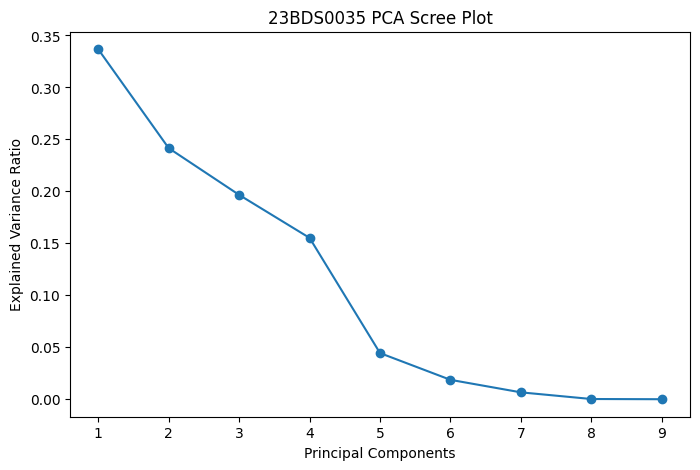

In [10]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_,
    marker='o'
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("23BDS0035 PCA Scree Plot")

plt.show()

8. Cumulative Explained Variance Plot

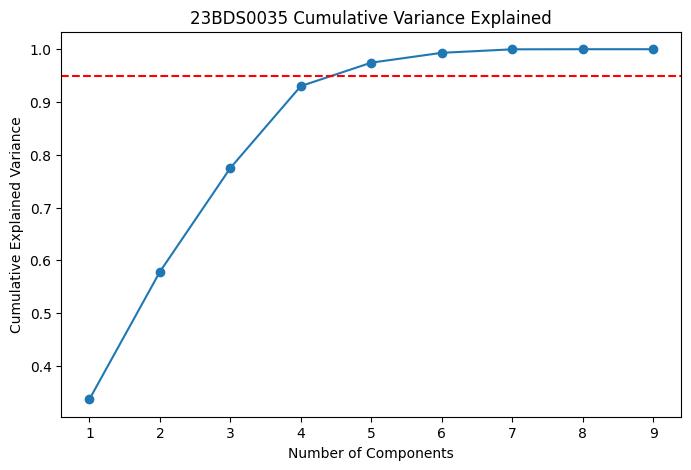

In [12]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    np.cumsum(pca.explained_variance_ratio_),
    marker='o'
)

plt.axhline(y=0.95, color='r', linestyle='--')

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("23BDS0035 Cumulative Variance Explained")

plt.show()

9. PCA 2D Visualization

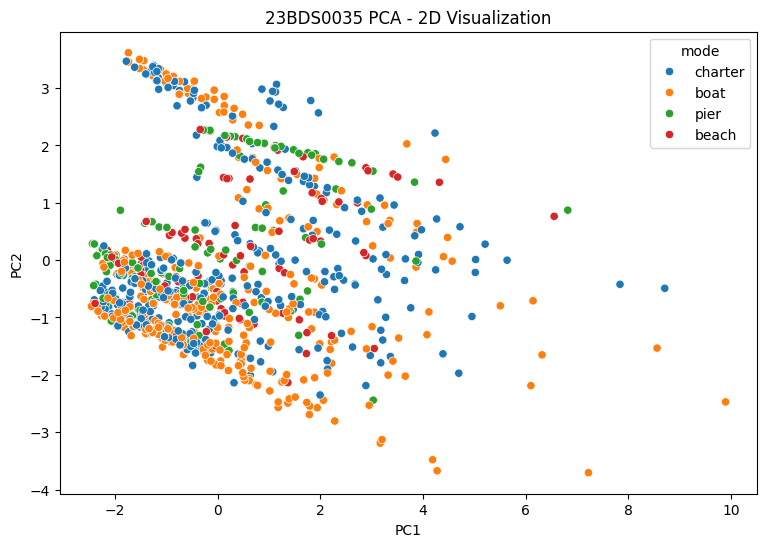

In [14]:
pca_2 = PCA(n_components=2)

X_2d = pca_2.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_2d, columns=['PC1', 'PC2'])

pca_df['mode'] = df['mode'].values

plt.figure(figsize=(9,6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='mode'
)

plt.title("23BDS0035 PCA - 2D Visualization")
plt.show()

MODULE 7 – LOGISTIC REGRESSION (CLASSIFICATION)

10. Define Features and Target

In [15]:
X = df.drop(
    columns=['rownames', 'mode', 'price', 'catch'],
    errors='ignore'
)

X = X.select_dtypes(include=np.number)

y = df['mode']

11. Split the Dataset

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

12. Standardize the Features

In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

13. Train Logistic Regression Model

In [18]:
model = LogisticRegression(max_iter=2000)

model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=2000)

14. Make Predictions

In [19]:
y_pred = model.predict(X_test_scaled)

print("Predicted Values:")
print(y_pred[:10])

print("Actual Values:")
print(y_test.iloc[:10].values)

Predicted Values:
['boat' 'pier' 'charter' 'pier' 'pier' 'boat' 'charter' 'charter'
 'charter' 'charter']
Actual Values:
['boat' 'charter' 'boat' 'pier' 'beach' 'charter' 'boat' 'charter' 'pier'
 'boat']


15. Evaluate the Model

In [20]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.5358649789029536
Accuracy Percentage: 53.58649789029536


Confusion Matrix

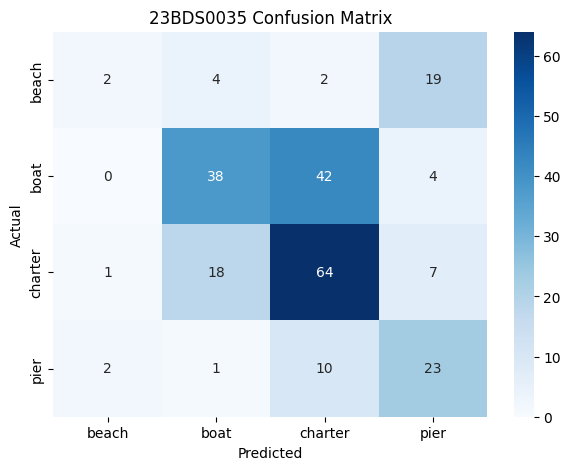

In [22]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("23BDS0035 Confusion Matrix")

plt.show()

Classification Report

In [23]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       beach       0.40      0.07      0.12        27
        boat       0.62      0.45      0.52        84
     charter       0.54      0.71      0.62        90
        pier       0.43      0.64      0.52        36

    accuracy                           0.54       237
   macro avg       0.50      0.47      0.45       237
weighted avg       0.54      0.54      0.51       237



16. Compare Actual and Predicted Values

In [24]:
result = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

result.head(15)

,Actual,Predicted
0,boat,boat
1,charter,pier
2,boat,charter
3,pier,pier
4,beach,pier
5,charter,boat
6,boat,charter
7,charter,charter
8,pier,charter
9,boat,charter


17. Conclusion


In Phase 3, Principal Component Analysis (PCA) was performed to reduce the dimensionality of the dataset while retaining important information. Scree plots and cumulative explained variance were used to analyze the principal components. Logistic Regression was then implemented to classify fishing modes based on the available features. The model was evaluated using accuracy, a confusion matrix, precision, recall, and F1-score. This phase helped in understanding dimensionality reduction and applying classification techniques to real-world data.